# A Scalable Hybrid Quantum-Classical QAOA Framework for Max-Cut-Based Community Detection

**Team:** Rohit Rao, Viraj Nalbalwar, Shreesh Kolhatkar, Om Shingare — COEP Tech, Group 3

This single notebook runs the whole project end to end and **produces every number quoted in the paper**.

| # | Section | Question it answers |
|---|---|---|
| 1 | Setup | Which software versions produced the results? |
| 2 | The network | What graph are we cutting? |
| 3 | Exact answer | What is the true best cut (brute force)? |
| 4 | Correctness checks | Is our simulator equal to Qiskit's? What was wrong in the old code? |
| 5 | The circuit | What does the quantum circuit look like? |
| 6 | Training QAOA | How good is the QAOA state at depth p = 1, 2, 3? |
| 7 | Sampling on Qiskit Aer | What would hardware-style measurements look like? |
| 8 | Many seeds | Are the results stable or lucky? |
| 9 | Classical baselines | Does QAOA beat Louvain / spectral / greedy / Goemans–Williamson / random sampling? |
| 10 | Noise | What happens on a noisy IBM-like device? |
| 11 | Real IBM hardware (optional) | Same on a real chip |
| 12 | Scalability | "Why only 16 nodes? What about Instagram?" |
| 13 | Save results | Writes `results/results.json` and figures |

**Core idea in plain words.** A social network is a graph. We want to split people into two groups so that the total
interaction weight *between* the groups is as large as possible (Max-Cut). Checking all $2^n$ splits is impossible for big
graphs. QAOA encodes every split as a basis state of $n$ qubits, runs a short circuit with $2p$ tunable angles
$(\gamma,\beta)$, and a classical optimiser (COBYLA) tunes the angles so that good splits become likely when we measure.

## 1. Setup

In [1]:
# ---- engine source (identical to engine/qaoa_engine.py used by the web backend) ----
"""QAOA Max-Cut engine shared by the notebook and the web backend.

Conventions (identical to Qiskit): bit i of a basis-state index is qubit i, and
qubit i is node i. Bitstrings returned by this module are in *node order*
(character i = node i), i.e. Qiskit count keys are reversed before use.
"""
from __future__ import annotations

import math
import time
from dataclasses import dataclass, field

import networkx as nx
import numpy as np
from scipy.optimize import minimize


# ----------------------------------------------------------------------------
# Graph input
# ----------------------------------------------------------------------------
def parse_network(text: str):
    """Parse the [NODES]/[EDGES] text format. Returns (G, names)."""
    section, idx, names, edges = None, {}, [], []
    for raw in text.splitlines():
        line = raw.strip()
        if not line or line.startswith("#"):
            continue
        if line.upper() == "[NODES]":
            section = "n"
            continue
        if line.upper() == "[EDGES]":
            section = "e"
            continue
        parts = line.split()
        if section == "n":
            if parts[0] in idx:
                raise ValueError(f"Duplicate node '{parts[0]}'")
            idx[parts[0]] = len(names)
            names.append(parts[0])
        elif section == "e":
            if len(parts) < 2:
                raise ValueError(f"Malformed edge line: '{line}'")
            for nm in parts[:2]:
                if nm not in idx:
                    raise ValueError(f"Edge references unknown node '{nm}'")
            w = float(parts[2]) if len(parts) > 2 else 1.0
            if w <= 0:
                raise ValueError(f"Edge weight must be positive: '{line}'")
            if parts[0] == parts[1]:
                raise ValueError(f"Self-loop not allowed: '{line}'")
            edges.append((idx[parts[0]], idx[parts[1]], w))
    if not names:
        raise ValueError("No nodes found - add a [NODES] section.")
    if not edges:
        raise ValueError("No edges found - add an [EDGES] section.")
    G = nx.Graph()
    for i, nm in enumerate(names):
        G.add_node(i, name=nm)
    for u, v, w in edges:
        G.add_edge(u, v, weight=w)
    return G, names


def graph_to_text(G, names) -> str:
    out = ["[NODES]", *names, "", "[EDGES]"]
    for u, v, d in G.edges(data=True):
        w = d.get("weight", 1)
        out.append(f"{names[u]} {names[v]} {w:g}")
    return "\n".join(out) + "\n"


def edge_arrays(G):
    e = np.array([(u, v, d.get("weight", 1.0)) for u, v, d in G.edges(data=True)])
    return e[:, 0].astype(int), e[:, 1].astype(int), e[:, 2].astype(float)


# ----------------------------------------------------------------------------
# Cost function
# ----------------------------------------------------------------------------
def cut_value(bits, G) -> float:
    """Weighted cut of a node-ordered bitstring / 0-1 sequence."""
    b = np.fromiter((int(c) for c in bits), dtype=np.int8) if isinstance(bits, str) else np.asarray(bits)
    u, v, w = edge_arrays(G)
    return float(np.sum(w * (b[u] != b[v])))


def basis_bits(n: int) -> np.ndarray:
    """(2^n, n) array; row = basis index, column i = bit of qubit i."""
    return ((np.arange(2**n)[:, None] >> np.arange(n)) & 1).astype(np.int8)


def cut_diagonal(G) -> np.ndarray:
    """Cut value of every one of the 2^n partitions (the diagonal of H_C)."""
    n = G.number_of_nodes()
    B = basis_bits(n)
    u, v, w = edge_arrays(G)
    d = np.zeros(2**n)
    for a, b, c in zip(u, v, w):
        d += c * (B[:, a] != B[:, b])
    return d


def index_to_bitstring(i: int, n: int) -> str:
    """Basis index -> node-ordered bitstring (character k = node k)."""
    return "".join(str((i >> k) & 1) for k in range(n))


def brute_force(G, diag=None):
    """Exact optimum by enumeration. Returns (best_cut, best_bitstring, n_optimal_states)."""
    d = cut_diagonal(G) if diag is None else diag
    best = d.max()
    idx = np.flatnonzero(np.isclose(d, best))
    return float(best), index_to_bitstring(int(idx[0]), G.number_of_nodes()), int(len(idx))


# ----------------------------------------------------------------------------
# Exact QAOA statevector simulation (fast, noiseless)
# ----------------------------------------------------------------------------
def _apply_mixer(psi, n, beta):
    c, s = math.cos(beta), -1j * math.sin(beta)
    for q in range(n):
        v = psi.reshape(2 ** (n - 1 - q), 2, 2**q)
        psi = (c * v + s * v[:, ::-1, :]).reshape(-1)
    return psi


def qaoa_probs(diag, n, gammas, betas) -> np.ndarray:
    """Measurement probabilities of |psi(gamma,beta)> = prod_k U_B(b_k) U_C(g_k) |+>^n."""
    psi = np.full(2**n, 2 ** (-n / 2), dtype=complex)
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * diag)
        psi = _apply_mixer(psi, n, b)
    p = np.abs(psi) ** 2
    return p / p.sum()


@dataclass
class QAOAResult:
    gammas: np.ndarray
    betas: np.ndarray
    probs: np.ndarray
    history: list = field(default_factory=list)  # objective value <C> per evaluation
    n_evals: int = 0
    seconds: float = 0.0
    restart_scores: list = field(default_factory=list)


def optimise_qaoa(diag, n, p, shots=None, max_iter=200, restarts=1, seed=42, rhobeg=0.5):
    """COBYLA over (gamma, beta).

    shots=None -> exact expectation; shots=S -> expectation estimated from S samples
    per evaluation (what hardware would give). Restart choice always uses the exact value.
    """
    rng = np.random.default_rng(seed)
    best, best_exact, scores = None, -np.inf, []
    t0 = time.time()
    for r in range(restarts):
        hist = []

        def obj(x):
            pr = qaoa_probs(diag, n, x[:p], x[p:])
            if shots is None:
                e = float(pr @ diag)
            else:
                e = float(rng.multinomial(shots, pr) @ diag / shots)
            hist.append(e)
            return -e

        x0 = np.concatenate([rng.uniform(0, np.pi, p), rng.uniform(0, np.pi / 2, p)])
        res = minimize(obj, x0, method="COBYLA", options={"maxiter": max_iter, "rhobeg": rhobeg})
        pr = qaoa_probs(diag, n, res.x[:p], res.x[p:])
        exact = float(pr @ diag)
        scores.append(exact)
        if exact > best_exact:
            best_exact = exact
            best = QAOAResult(res.x[:p].copy(), res.x[p:].copy(), pr, hist, len(hist))
    best.seconds = time.time() - t0
    best.restart_scores = scores
    return best


def summarise(res: QAOAResult, diag, n, shots=2048, seed=0):
    """Honest quality metrics for a trained QAOA state."""
    opt = float(diag.max())
    mean_rand = float(diag.mean())
    exp_c = float(res.probs @ diag)
    p_opt = float(res.probs[np.isclose(diag, opt)].sum())
    counts = np.random.default_rng(seed).multinomial(shots, res.probs)
    sampled = np.flatnonzero(counts)
    best_idx = int(sampled[np.argmax(diag[sampled])])
    top_idx = int(np.argmax(res.probs))
    return {
        "optimum": opt,
        "random_mean": mean_rand,
        "expected_cut": exp_c,
        "expected_ratio": exp_c / opt,
        "p_optimal": p_opt,
        "best_sampled_cut": float(diag[best_idx]),
        "best_sampled_ratio": float(diag[best_idx]) / opt,
        "best_sampled_bitstring": index_to_bitstring(best_idx, n),
        "most_probable_bitstring": index_to_bitstring(top_idx, n),
        "most_probable_cut": float(diag[top_idx]),
        "counts": counts,
    }


# ----------------------------------------------------------------------------
# Qiskit circuit (what would run on hardware) and cross-checks
# ----------------------------------------------------------------------------
def build_qaoa_circuit(G, p, measure=True):
    """Parameterised QAOA circuit.  U_C(g) = exp(-i g H_C) = RZZ(-g*w) per edge (up to a global phase)."""
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector

    n = G.number_of_nodes()
    gam, bet = ParameterVector("gamma", p), ParameterVector("beta", p)
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for k in range(p):
        qc.barrier()
        for u, v, d in G.edges(data=True):
            qc.rzz(-gam[k] * d.get("weight", 1.0), u, v)
        qc.barrier()
        for q in range(n):
            qc.rx(2 * bet[k], q)
    if measure:
        qc.measure_all()
    return qc


def bind(qc, gammas, betas):
    """Bind by name; qc.parameters is alphabetical (beta before gamma), so positional zip would swap them."""
    m = {q.name: q for q in qc.parameters}
    vals = {f"gamma[{i}]": g for i, g in enumerate(gammas)}
    vals.update({f"beta[{i}]": b for i, b in enumerate(betas)})
    return qc.assign_parameters({m[k]: v for k, v in vals.items()})


def circuit_probs(G, p, gammas, betas) -> np.ndarray:
    """Probabilities from Qiskit's own statevector, for verifying the numpy engine."""
    from qiskit.quantum_info import Statevector

    qc = build_qaoa_circuit(G, p, measure=False)
    return Statevector(bind(qc, gammas, betas)).probabilities()


def sample_circuit(G, p, gammas, betas, shots=2048, noise_backend=None, seed=7, optimization_level=3):
    """Run the Qiskit circuit on AerSimulator (ideal, or noisy if a fake backend is given).

    Returns {node-ordered bitstring: count} and the transpiled circuit.
    """
    from qiskit import transpile
    from qiskit_aer import AerSimulator

    qc = build_qaoa_circuit(G, p)
    bound = bind(qc, gammas, betas)
    sim = AerSimulator.from_backend(noise_backend) if noise_backend is not None else AerSimulator()
    t = transpile(bound, sim, optimization_level=optimization_level, seed_transpiler=seed)
    counts = sim.run(t, shots=shots, seed_simulator=seed).result().get_counts()
    return {k[::-1]: v for k, v in counts.items()}, t


# ----------------------------------------------------------------------------
# Classical baselines
# ----------------------------------------------------------------------------
def greedy_flip(G, restarts=10, seed=0):
    """1-flip local search from random starts."""
    rng = np.random.default_rng(seed)
    n = G.number_of_nodes()
    adj = [[(j, d.get("weight", 1.0)) for j, d in G[i].items()] for i in range(n)]
    best, best_b = -1.0, None
    for _ in range(restarts):
        z = rng.integers(0, 2, n)
        improved = True
        while improved:
            improved = False
            for i in rng.permutation(n):
                gain = sum(w * (1 if z[i] == z[j] else -1) for j, w in adj[i])
                if gain > 1e-12:
                    z[i] ^= 1
                    improved = True
        c = cut_value(z, G)
        if c > best:
            best, best_b = c, z.copy()
    return best, "".join(map(str, best_b))


def spectral_bisection(G):
    """Sign of the dominant eigenvector of the weighted Laplacian."""
    import scipy.sparse as sp
    import scipy.sparse.linalg as sla

    n = G.number_of_nodes()
    L = nx.laplacian_matrix(G, nodelist=range(n), weight="weight").astype(float)
    if n <= 400:
        vals, vecs = np.linalg.eigh(L.toarray())
        vec = vecs[:, -1]
    else:
        _, vecs = sla.eigsh(L, k=1, which="LA")
        vec = vecs[:, 0]
    z = (vec > 0).astype(int)
    return cut_value(z, G), "".join(map(str, z))


def louvain_two_way(G, seed=0):
    """Louvain communities, merged into two groups by exhaustive search over community colourings."""
    comms = nx.community.louvain_communities(G, weight="weight", seed=seed)
    k = len(comms)
    label = {}
    for ci, c in enumerate(comms):
        for v in c:
            label[v] = ci
    u, v, w = edge_arrays(G)
    cu, cv = np.array([label[a] for a in u]), np.array([label[b] for b in v])
    if k > 20:
        k = 20
        cu, cv = cu % 20, cv % 20
    best, best_mask = -1.0, 0
    for mask in range(2 ** (k - 1)):
        col = (mask >> np.arange(k)) & 1
        c = float(np.sum(w * (col[cu] != col[cv])))
        if c > best:
            best, best_mask = c, mask
    col = (best_mask >> np.arange(k)) & 1
    z = "".join(str(int(col[label[i] % k])) for i in range(G.number_of_nodes()))
    return cut_value(z, G), z, len(comms)


def goemans_williamson(G, trials=20, seed=0):
    """SDP relaxation + random-hyperplane rounding. Returns (avg_cut, best_cut, sdp_upper_bound, best_bitstring)."""
    import cvxpy as cp

    n = G.number_of_nodes()
    W = nx.to_numpy_array(G, nodelist=range(n), weight="weight")
    X = cp.Variable((n, n), PSD=True)
    obj = cp.Maximize(0.25 * cp.sum(cp.multiply(W, 1 - X)))
    prob = cp.Problem(obj, [cp.diag(X) == 1])
    prob.solve(solver=cp.SCS, eps=1e-6)
    ub = float(prob.value)
    vals, vecs = np.linalg.eigh(X.value)
    V = vecs * np.sqrt(np.clip(vals, 0, None))
    rng = np.random.default_rng(seed)
    cuts, best, best_z = [], -1.0, None
    for _ in range(trials):
        z = (V @ rng.normal(size=n) > 0).astype(int)
        c = cut_value(z, G)
        cuts.append(c)
        if c > best:
            best, best_z = c, z
    return float(np.mean(cuts)), float(best), ub, "".join(map(str, best_z))


# ----------------------------------------------------------------------------
# Scalable hybrid: block-coordinate QAOA for graphs far beyond qubit limits
# ----------------------------------------------------------------------------
def _bfs_blocks(G, k, rng):
    """Split nodes into connected-ish chunks of at most k nodes (random BFS order)."""
    seen, blocks = set(), []
    nodes = list(G.nodes())
    for s in rng.permutation(nodes):
        s = int(s)
        if s in seen:
            continue
        queue, cur = [s], []
        seen.add(s)
        while queue and len(cur) < k:
            x = queue.pop(0)
            cur.append(x)
            nb = [int(y) for y in G[x] if y not in seen]
            rng.shuffle(nb)
            for y in nb:
                seen.add(y)
                queue.append(y)
        # unvisited queued nodes are released for later blocks
        for y in queue:
            seen.discard(y)
        blocks.append(cur)
    return blocks


def block_diag(G, block, z):
    """Cut contribution of `block` as a diagonal over its 2^k states, with the rest of z fixed."""
    k = len(block)
    B = basis_bits(k)
    pos = {v: i for i, v in enumerate(block)}
    d = np.zeros(2**k)
    for v in block:
        for nb, dat in G[v].items():
            w = dat.get("weight", 1.0)
            if nb in pos:
                if pos[v] < pos[nb]:
                    d += w * (B[:, pos[v]] != B[:, pos[nb]])
            else:
                d += w * (B[:, pos[v]] != z[nb])
    return d


def block_qaoa(G, block_size=12, p=2, sweeps=3, shots=1024, max_iter=60, seed=0, z0=None, log=None):
    """Hybrid solver: fix everything but a <=block_size block, solve that block with QAOA, repeat.

    A block update is accepted only if it does not lower the cut, so the result is never worse than z0.
    Each block needs only `block_size` qubits regardless of the full graph size.
    """
    rng = np.random.default_rng(seed)
    n = G.number_of_nodes()
    z = rng.integers(0, 2, n).astype(np.int8) if z0 is None else np.array(z0, dtype=np.int8)
    trace, n_blocks, t0 = [cut_value(z, G)], 0, time.time()
    for s in range(sweeps):
        for block in _bfs_blocks(G, block_size, rng):
            k = len(block)
            if k < 2:
                continue
            d = block_diag(G, block, z)
            res = optimise_qaoa(d, k, p, shots=None, max_iter=max_iter, seed=int(rng.integers(1 << 30)))
            counts = rng.multinomial(shots, res.probs)
            cand = np.flatnonzero(counts)
            best = int(cand[np.argmax(d[cand])])
            cur = int(sum(int(z[v]) << i for i, v in enumerate(block)))
            if d[best] > d[cur]:
                for i, v in enumerate(block):
                    z[v] = (best >> i) & 1
            n_blocks += 1
        trace.append(cut_value(z, G))
        if log:
            log(f"sweep {s + 1}/{sweeps}: cut = {trace[-1]:.1f}")
    return {
        "z": z,
        "cut": trace[-1],
        "trace": trace,
        "blocks_solved": n_blocks,
        "seconds": time.time() - t0,
        "qubits_per_block": block_size,
    }


def make_social_graph(n, m=3, seed=0, wmax=3):
    """Scale-free (Barabasi-Albert) graph with integer interaction weights 1..wmax."""
    rng = np.random.default_rng(seed)
    G = nx.barabasi_albert_graph(n, m, seed=seed)
    for u, v in G.edges():
        G[u][v]["weight"] = float(rng.integers(1, wmax + 1))
    return G

In [2]:
import json, os, time, platform, warnings
from pathlib import Path
import numpy as np, networkx as nx, pandas as pd
import matplotlib.pyplot as plt
import qiskit, qiskit_aer, scipy
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGS = ROOT / "results" / "figs"; FIGS.mkdir(parents=True, exist_ok=True)
R = {}      # every reported number is collected here and saved in section 13

SEED, SHOTS, MAX_ITER, RESTARTS = 42, 2048, 300, 5
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.grid": True, "grid.alpha": .25})
C_A, C_B, C_CUT = "#2563eb", "#e11d48", "#f59e0b"

R["versions"] = dict(python=platform.python_version(), qiskit=qiskit.__version__, qiskit_aer=qiskit_aer.__version__,
                     numpy=np.__version__, scipy=scipy.__version__, networkx=nx.__version__)
R["config"] = dict(seed=SEED, shots=SHOTS, max_iter=MAX_ITER, restarts=RESTARTS)
print(R["versions"])

{'python': '3.14.8', 'qiskit': '2.6.0', 'qiskit_aer': '0.18.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'networkx': '3.7'}


## 2. The network
The 16-user graph from the paper (`network.txt`, embedded here so the notebook is self-contained). Edge weight = interaction
strength (1 occasional, 2 regular, 3 frequent). You can paste any other graph in the same `[NODES]` / `[EDGES]` format.

In [3]:
NETWORK_TEXT = """# ============================================================
#  SOCIAL NETWORK DEFINITION
#  Edit this file to change the users and connections.
#
#  NODES section  → one user per line:  Name
#  EDGES section  → one connection per line:  Name1  Name2  Weight
#
#  Rules:
#   - Lines starting with # are comments (ignored)
#   - Blank lines are ignored
#   - Node names must be a single word (no spaces), e.g. "Rohit" ✓ "Rohit Smith" ✗
#   - Edge weight = interaction strength (positive number, e.g. 1, 2, 3)
#   - Both names in an EDGE must exist in the NODES section
# ============================================================

[NODES]
# ── Original 6 nodes ──────────────────────────────────────
Rohit
Bob
Carol
Dave
Eve
Frank
# ── 10 newly added nodes ──────────────────────────────────
Grace
Henry
Isla
Jack
Karen
Leo
Mia
Nathan
Olivia
Peter

[EDGES]
# Format:  NodeA   NodeB   Weight
# Weight = interaction / influence strength (higher = stronger connection)

# ── Original edges ────────────────────────────────────────
Rohit   Bob     3
Rohit   Carol   2
Rohit   Dave    1
Bob     Carol   2
Bob     Eve     3
Carol   Dave    2
Carol   Eve     2
Dave    Frank   3
Eve     Frank   2

# ── Edges for new nodes ───────────────────────────────────
Frank   Grace   2
Grace   Henry   3
Grace   Isla    1
Henry   Jack    2
Henry   Karen   3
Isla    Leo     2
Jack    Mia     1
Karen   Nathan  3
Leo     Olivia  2
Mia     Peter   3
Nathan  Olivia  1
Olivia  Peter   2
Peter   Rohit   1
Grace   Bob     2
Henry   Carol   1
Karen   Eve     2
Mia     Dave    1
"""

16 nodes, 26 edges, total weight 52, max degree 5


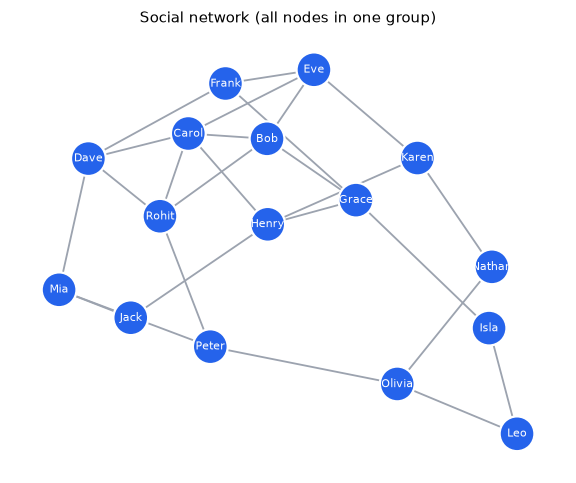

In [4]:
G, names = parse_network(NETWORK_TEXT)
n, m = G.number_of_nodes(), G.number_of_edges()
W_total = sum(d["weight"] for *_, d in G.edges(data=True))
R["graph"] = dict(nodes=n, edges=m, total_weight=W_total, degrees=sorted(dict(G.degree()).values(), reverse=True))
print(f"{n} nodes, {m} edges, total weight {W_total:g}, max degree {max(dict(G.degree()).values())}")

POS = nx.spring_layout(G, seed=49, k=1.0, weight=None, iterations=300)

def draw_partition(G, bits, ax, title=""):
    cutE = [(u, v) for u, v in G.edges() if bits[u] != bits[v]]
    keep = [(u, v) for u, v in G.edges() if bits[u] == bits[v]]
    nx.draw_networkx_edges(G, POS, edgelist=keep, ax=ax, edge_color="#9ca3af", width=1.2)
    nx.draw_networkx_edges(G, POS, edgelist=cutE, ax=ax, edge_color=C_CUT, width=2.6, style="dashed")
    nx.draw_networkx_nodes(G, POS, ax=ax, node_color=[C_A if bits[i] == "0" else C_B for i in G.nodes()],
                           node_size=520, edgecolors="white", linewidths=1.5)
    nx.draw_networkx_labels(G, POS, labels={i: names[i] for i in G.nodes()}, ax=ax, font_size=7, font_color="white")
    ax.set_title(title, fontsize=10); ax.axis("off")

fig, ax = plt.subplots(figsize=(6.5, 5.2)); draw_partition(G, "0" * n, ax, "Social network (all nodes in one group)")
plt.show()

## 3. The exact answer (brute force)
With $n=16$ there are only $2^{16}=65{,}536$ splits, so we can score all of them at once and know the **true optimum**.
(The earlier paper draft said this takes ~10 hours; vectorised it takes a few hundredths of a second.)

Optimum cut = 44  (6 optimal bit patterns = 3 partitions x 2 label swaps)  in 0.014s
A random split cuts 26 on average (59.1% of optimum)


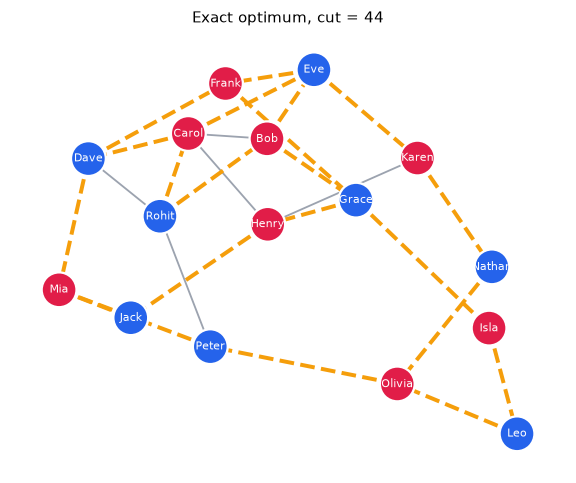

In [5]:
t0 = time.time(); diag = cut_diagonal(G); OPT, OPT_BITS, N_OPT = brute_force(G, diag); t_bf = time.time() - t0
random_mean = float(diag.mean())
R["brute_force"] = dict(optimum=OPT, n_optimal_states=N_OPT, example_bitstring=OPT_BITS, seconds=round(t_bf, 4),
                        random_mean_cut=random_mean, partitions=2**n)
print(f"Optimum cut = {OPT:g}  ({N_OPT} optimal bit patterns = {N_OPT//2} partitions x 2 label swaps)  in {t_bf:.3f}s")
print(f"A random split cuts {random_mean:g} on average ({random_mean/OPT:.1%} of optimum)")
fig, ax = plt.subplots(figsize=(6.5, 5.2)); draw_partition(G, OPT_BITS, ax, f"Exact optimum, cut = {OPT:g}"); plt.show()

## 4. Correctness checks
### 4a. Our fast simulator equals Qiskit
The training loop uses a NumPy statevector simulator (exact, ~100x faster than shot-by-shot Aer). Here we prove it gives the same
probabilities as Qiskit's own circuit.

### 4b. Bugs found in the original `qaoa_social_network.py`
1. **Bit order.** Qiskit prints qubit 0 as the *rightmost* character, but the old code scored `bitstring[u]` left-to-right, so the optimiser
   was evaluating a *mirrored* graph.
2. **Cost-gate angle.** The old circuit used `rzz(2*gamma*w)`; the paper's cost unitary $e^{-i\gamma H_C}$ equals `rzz(-gamma*w)` (up to a global phase).
3. **Parameter order.** `qc.parameters` is alphabetical (beta before gamma), so the old code bound gammas to the beta slots and reported them swapped.

In [6]:
g_test, b_test = [0.7, 0.3], [0.4, 0.9]
err = np.abs(qaoa_probs(diag, n, g_test, b_test) - circuit_probs(G, 2, g_test, b_test)).max()
print(f"max |P_numpy - P_qiskit| = {err:.2e}")
R["checks"] = dict(numpy_vs_qiskit_max_prob_error=float(err))

# bit-order demo: an optimal partition, written the way Qiskit reports it, scored the old (wrong) way
qiskit_key = OPT_BITS[::-1]
old_way = cut_value(qiskit_key, G); right_way = cut_value(OPT_BITS, G)
print(f"Optimal partition scored correctly: {right_way:g};  same Qiskit key scored left-to-right (old code): {old_way:g}")
R["checks"]["legacy_bitorder_demo"] = dict(correct=right_way, legacy=old_way)

max |P_numpy - P_qiskit| = 3.14e-18
Optimal partition scored correctly: 44;  same Qiskit key scored left-to-right (old code): 33


## 5. The QAOA circuit
One qubit per user. Hadamards create the uniform superposition, then $p$ rounds of **cost** (an `RZZ` per friendship, rewarding cut edges) and **mixer** (`RX` on every qubit).

In [7]:
qc2 = build_qaoa_circuit(G, 2)
from qiskit import transpile
ops = dict(qc2.count_ops()); tq = transpile(qc2.remove_final_measurements(inplace=False), basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
R["circuit_p2"] = dict(qubits=n, rzz=ops.get("rzz"), rx=ops.get("rx"), h=ops.get("h"), cx_after_transpile=tq.count_ops().get("cx"), depth_after_transpile=tq.depth())
print(R["circuit_p2"])
qc_small = build_qaoa_circuit(G, 1, measure=False)
fig = qc_small.draw("mpl", fold=40, scale=.5); fig.savefig(FIGS / "circuit_p1.png", bbox_inches="tight"); plt.show()

{'qubits': 16, 'rzz': 52, 'rx': 32, 'h': 16, 'cx_after_transpile': 104, 'depth_after_transpile': 91}


## 6. Training QAOA at p = 1, 2, 3
Each COBYLA step measures the circuit with 2048 shots and estimates $\langle C\rangle$ (shot noise included, like real hardware); we keep
the best of 5 random starts. We report **honest metrics**, not only the best bitstring we happened to sample:

* **expected-cut ratio** $\langle C\rangle/\text{OPT}$ — quality of the whole distribution (a random split scores 0.59 here)
* **P(optimal)** — chance a single measurement is an optimal cut
* **best of 2048 shots** — what you would report after sampling (also reached by pure random sampling, see Section 9)

,params,evals,expected_cut,expected_ratio,P_optimal,enrichment_vs_random,best_of_shots,best_of_shots_ratio,most_probable_cut,seconds
p,,,,,,,,,,
1,2,36,35.1510,0.7989,0.0107,116.9749,44.0,1.0,44.0,2.6110
2,4,53,35.0113,0.7957,0.0100,109.3822,44.0,1.0,44.0,6.0876
3,6,67,37.2606,0.8468,0.0280,305.5001,44.0,1.0,44.0,15.0641


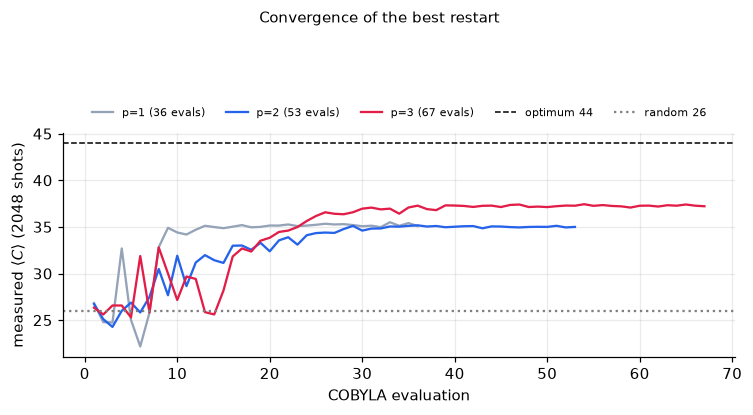

In [8]:
TRAIN = {}
rows = []
for p in (1, 2, 3):
    res = optimise_qaoa(diag, n, p, shots=SHOTS, max_iter=MAX_ITER, restarts=RESTARTS, seed=SEED)
    s = summarise(res, diag, n, shots=SHOTS, seed=SEED)
    TRAIN[p] = (res, s)
    rows.append(dict(p=p, params=2*p, evals=res.n_evals, expected_cut=s["expected_cut"], expected_ratio=s["expected_ratio"],
                     P_optimal=s["p_optimal"], enrichment_vs_random=s["p_optimal"] / (N_OPT / 2**n), best_of_shots=s["best_sampled_cut"], best_of_shots_ratio=s["best_sampled_ratio"],
                     most_probable_cut=s["most_probable_cut"], seconds=res.seconds))
df_train = pd.DataFrame(rows).set_index("p"); display(df_train.round(4))
R["training"] = {int(p): dict(r, gammas=TRAIN[p][0].gammas.round(4).tolist(), betas=TRAIN[p][0].betas.round(4).tolist(),
                                best_bitstring=TRAIN[p][1]["best_sampled_bitstring"])
                 for p, r in zip(df_train.index, df_train.to_dict("records"))}

fig, ax = plt.subplots(figsize=(7, 3.8))
for p, col in zip((1, 2, 3), ("#94a3b8", C_A, C_B)):
    h = TRAIN[p][0].history; ax.plot(range(1, len(h)+1), h, color=col, label=f"p={p} ({len(h)} evals)")
ax.axhline(OPT, ls="--", c="k", lw=1, label=f"optimum {OPT:g}"); ax.axhline(random_mean, ls=":", c="gray", label=f"random {random_mean:g}")
ax.set(xlabel="COBYLA evaluation", ylabel=r"measured $\langle C \rangle$ (2048 shots)")
fig.suptitle("Convergence of the best restart", y=0.98, fontsize=10)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5, fontsize=7, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.88])
fig.savefig(FIGS / "convergence.png", bbox_inches="tight"); plt.show()

## 7. Sampling the trained circuit on Qiskit Aer
Now we run the actual Qiskit circuit (not our NumPy shortcut) at the trained angles and look at what is measured.

Aer sampled <C> = 35.27  (exact 35.01);  best sampled cut = 44;  bitstring 0110010110001110


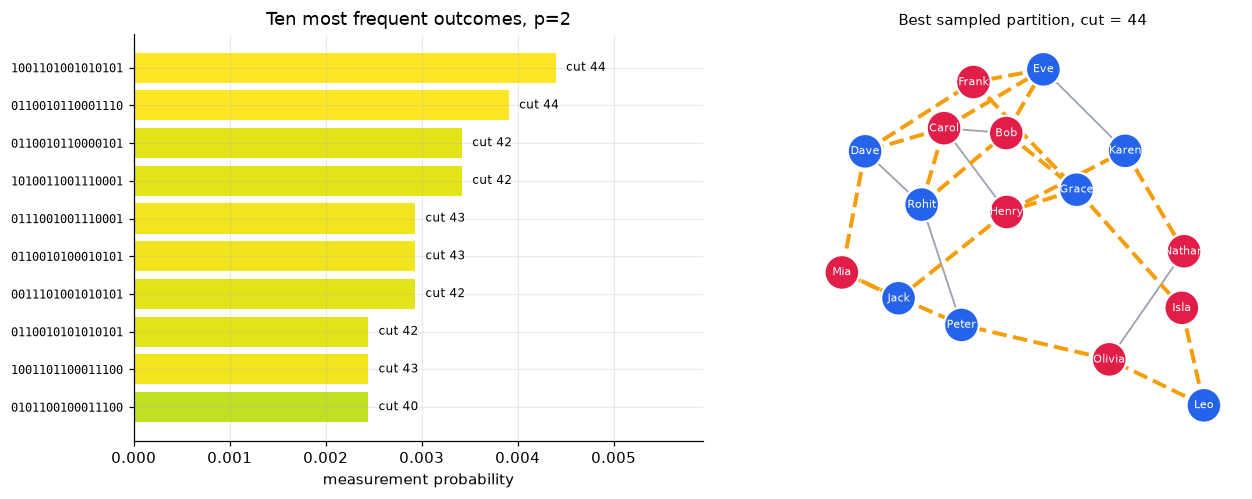

Group A: Rohit, Dave, Eve, Grace, Jack, Karen, Leo, Peter
Group B: Bob, Carol, Frank, Henry, Isla, Mia, Nathan, Olivia


In [9]:
P_SHOW = 2
res2, s2 = TRAIN[P_SHOW]
counts, tcirc = sample_circuit(G, P_SHOW, res2.gammas, res2.betas, shots=SHOTS, seed=SEED)
cuts = {k: cut_value(k, G) for k in counts}
best_key = max(cuts, key=cuts.get)
exp_aer = sum(counts[k] * cuts[k] for k in counts) / SHOTS
print(f"Aer sampled <C> = {exp_aer:.2f}  (exact {s2['expected_cut']:.2f});  best sampled cut = {cuts[best_key]:g};  bitstring {best_key}")
R["aer_sampling_p2"] = dict(expected_cut=exp_aer, best_cut=cuts[best_key], best_bitstring=best_key)

top = sorted(counts.items(), key=lambda kv: -kv[1])[:10]
plot_top = list(reversed(top))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
cm = plt.cm.viridis; mx = OPT
ys = np.arange(len(plot_top))
probs = [c / SHOTS for _, c in plot_top]
axs[0].barh(ys, probs, color=[cm(cuts[k] / mx) for k, _ in plot_top])
for y, (k, c) in zip(ys, plot_top):
    axs[0].text(c / SHOTS + max(probs) * 0.025, y, f"cut {cuts[k]:g}", va="center", fontsize=8)
axs[0].set_yticks(ys); axs[0].set_yticklabels([k for k, _ in plot_top], fontfamily="monospace", fontsize=8)
axs[0].set_xlim(0, max(probs) * 1.35)
axs[0].set(xlabel="measurement probability", title=f"Ten most frequent outcomes, p={P_SHOW}")
draw_partition(G, best_key, axs[1], f"Best sampled partition, cut = {cuts[best_key]:g}")
fig.savefig(FIGS / "probabilities_partition.png", bbox_inches="tight"); plt.show()

grpA = [names[i] for i, b in enumerate(best_key) if b == "0"]; grpB = [names[i] for i, b in enumerate(best_key) if b == "1"]
print("Group A:", ", ".join(grpA)); print("Group B:", ", ".join(grpB))
R["partition_p2"] = dict(group_a=grpA, group_b=grpB, cut_edges=int(sum(best_key[u] != best_key[v] for u, v in G.edges())))

## 8. Are the results stable? (10 independent seeds)
A single run can be lucky. We repeat the whole training with 10 different random initialisations and shot-noise seeds and report mean ± standard deviation.

,expected_ratio_mean,expected_ratio_std,P_opt_mean,best_of_shots_mean,best_of_shots_min,evals_mean
p,,,,,,
1,0.7036,0.0998,0.0054,43.5,42.0,29.1
2,0.7102,0.1009,0.0070,43.2,41.0,41.8
3,0.7230,0.0872,0.0073,43.6,42.0,62.4


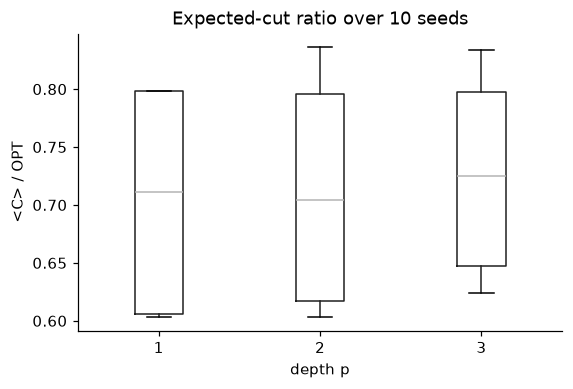

In [10]:
SEEDS = range(10); stab = []
for p in (1, 2, 3):
    for sd in SEEDS:
        r_ = optimise_qaoa(diag, n, p, shots=SHOTS, max_iter=MAX_ITER, restarts=1, seed=1000 + sd)
        s_ = summarise(r_, diag, n, shots=SHOTS, seed=sd)
        stab.append(dict(p=p, seed=sd, expected_ratio=s_["expected_ratio"], P_optimal=s_["p_optimal"], best_of_shots=s_["best_sampled_cut"], evals=r_.n_evals))
df_stab = pd.DataFrame(stab)
summary = df_stab.groupby("p").agg(expected_ratio_mean=("expected_ratio", "mean"), expected_ratio_std=("expected_ratio", "std"),
                                   P_opt_mean=("P_optimal", "mean"), best_of_shots_mean=("best_of_shots", "mean"),
                                   best_of_shots_min=("best_of_shots", "min"), evals_mean=("evals", "mean"))
display(summary.round(4)); R["stability_10_seeds"] = {int(k): v for k, v in summary.round(5).to_dict("index").items()}
fig, ax = plt.subplots(figsize=(5.5, 3.6)); df_stab.boxplot(column="expected_ratio", by="p", ax=ax, grid=False)
ax.set(title="Expected-cut ratio over 10 seeds", xlabel="depth p", ylabel="<C> / OPT"); plt.suptitle(""); fig.savefig(FIGS / "depth_stability.png", bbox_inches="tight"); plt.show()

## 9. Classical baselines and the random-sampling control
All methods run on the *same* graph. **Random sampling (2048 draws)** is the critical control: with only 65,536 states, simply guessing 2048 times already lands near the top,
so "best of 2048 shots" alone does not prove quantum value on a graph this small. This is why we also report $\langle C\rangle$ and P(optimal), and why Section 12 moves to graphs where brute force is impossible.

In [11]:
rng = np.random.default_rng(0)
rs_best = np.array([diag[rng.integers(0, 2**n, SHOTS)].max() for _ in range(500)])
gr = greedy_flip(G, restarts=10, seed=0); sp_ = spectral_bisection(G); lv = louvain_two_way(G)
t0 = time.time(); gw_avg, gw_best, gw_ub, _ = goemans_williamson(G, trials=20, seed=0); t_gw = time.time() - t0
q1, q2, q3 = (TRAIN[p][1] for p in (1, 2, 3))
tab = [("Random split (mean)", random_mean), ("Random sampling, best of 2048 (mean of 500 trials)", rs_best.mean()),
       ("Louvain + 2-way merge", lv[0]), ("Greedy 1-flip (10 restarts)", gr[0]), ("Spectral bisection", sp_[0]),
       ("Goemans-Williamson (avg of 20 roundings)", gw_avg), ("Goemans-Williamson (best of 20)", gw_best),
       ("QAOA p=1  best of 2048 shots", q1["best_sampled_cut"]), ("QAOA p=2  best of 2048 shots", q2["best_sampled_cut"]),
       ("QAOA p=3  best of 2048 shots", q3["best_sampled_cut"]),
       ("QAOA p=1  expected <C>", q1["expected_cut"]), ("QAOA p=2  expected <C>", q2["expected_cut"]), ("QAOA p=3  expected <C>", q3["expected_cut"]),
       ("Brute force optimum", OPT)]
df_cmp = pd.DataFrame(tab, columns=["method", "cut"]); df_cmp["ratio_%"] = (100 * df_cmp.cut / OPT).round(1); display(df_cmp.round(2))
R["comparison"] = {r["method"]: dict(cut=round(float(r["cut"]), 3), ratio_pct=r["ratio_%"]) for r in df_cmp.to_dict("records")}
R["comparison_extra"] = dict(gw_sdp_upper_bound=gw_ub, gw_seconds=t_gw, louvain_communities=lv[2], random_sampling_hit_optimum_pct=float((rs_best >= OPT).mean() * 100))
print(f"Random sampling reaches the optimum in {(rs_best >= OPT).mean():.0%} of 500 trials; SDP upper bound = {gw_ub:.2f}")

,method,cut,ratio_%
0,Random split (mean),26.00,59.1
1,"Random sampling, best of 2048 (mean of 500 tri...",42.41,96.4
2,Louvain + 2-way merge,10.00,22.7
3,Greedy 1-flip (10 restarts),44.00,100.0
4,Spectral bisection,39.00,88.6
5,Goemans-Williamson (avg of 20 roundings),41.95,95.3
6,Goemans-Williamson (best of 20),44.00,100.0
7,QAOA p=1 best of 2048 shots,44.00,100.0
8,QAOA p=2 best of 2048 shots,44.00,100.0
9,QAOA p=3 best of 2048 shots,44.00,100.0


Random sampling reaches the optimum in 14% of 500 trials; SDP upper bound = 45.78


## 10. Noise: what a real (imperfect) quantum chip does
We train the angles noiselessly, then *execute the same circuit* on Qiskit Aer using the calibration data of a real IBM 127-qubit Eagle processor (`FakeSherbrooke`: gate errors, readout errors, decoherence), after transpiling to its native gates and connectivity.

In [12]:
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
backend = FakeSherbrooke(); NOISE = {}
for p in (1, 2):
    res_, s_ = TRAIN[p]; t0 = time.time()
    c_noisy, tc = sample_circuit(G, p, res_.gammas, res_.betas, shots=SHOTS, noise_backend=backend, seed=SEED)
    e_noisy = sum(v * cut_value(k, G) for k, v in c_noisy.items()) / SHOTS
    best_noisy = max(cut_value(k, G) for k in c_noisy)
    ops_ = tc.count_ops(); two_q = sum(v for k, v in ops_.items() if k in ("ecr", "cx", "cz"))
    NOISE[p] = dict(ideal_expected=s_["expected_cut"], noisy_expected=e_noisy, ideal_ratio=s_["expected_ratio"], noisy_ratio=e_noisy / OPT,
                    best_noisy=best_noisy, two_qubit_gates=int(two_q), depth=tc.depth(), seconds=round(time.time() - t0, 1))
df_noise = pd.DataFrame(NOISE).T; display(df_noise.round(3)); R["noise_fake_sherbrooke"] = {int(k): v for k, v in NOISE.items()}
print(f"Random-guess level = {random_mean:g}: noise pushes <C> toward it as the circuit gets deeper.")

,ideal_expected,noisy_expected,ideal_ratio,noisy_ratio,best_noisy,two_qubit_gates,depth,seconds
1,35.151,32.673,0.799,0.743,44.0,127.0,322.0,30.5
2,35.011,30.004,0.796,0.682,44.0,251.0,642.0,28.0


Random-guess level = 26: noise pushes <C> toward it as the circuit gets deeper.


## 11. (Optional) Real IBM quantum hardware
Disabled by default. To use it: create a free IBM Quantum Platform account, then set the token in your shell **before** starting Jupyter
(`export IBM_QUANTUM_TOKEN=...`) — never paste a token into a notebook that you share or commit. Then set `RUN_HARDWARE = True`.
We run the trained p=1 circuit (fewest two-qubit gates) with the Qiskit Runtime `SamplerV2` primitive.

In [13]:
RUN_HARDWARE = False
if RUN_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=os.environ["IBM_QUANTUM_TOKEN"])
    backend_hw = service.least_busy(operational=True, simulator=False, min_num_qubits=n)
    res_, s_ = TRAIN[1]
    qc_hw = bind(build_qaoa_circuit(G, 1), res_.gammas, res_.betas)
    isa = generate_preset_pass_manager(backend=backend_hw, optimization_level=3).run(qc_hw)
    job = SamplerV2(mode=backend_hw).run([isa], shots=SHOTS); print("job", job.job_id(), "on", backend_hw.name)
    pub = job.result()[0]; raw = pub.data.meas.get_counts()
    c_hw = {k[::-1]: v for k, v in raw.items()}
    e_hw = sum(v * cut_value(k, G) for k, v in c_hw.items()) / SHOTS
    R["hardware_p1"] = dict(backend=backend_hw.name, expected_cut=e_hw, ratio=e_hw / OPT, best=max(cut_value(k, G) for k in c_hw), job_id=job.job_id())
    print(R["hardware_p1"])
else:
    print("Hardware run skipped (RUN_HARDWARE = False).")

Hardware run skipped (RUN_HARDWARE = False).


## 12. Scalability — "Why only 16 nodes? Instagram has billions of users."

**Short answer.** Nobody solves a billion-node graph as *one* circuit — not a quantum computer, not a supercomputer. A real pipeline is *hybrid in structure*:
classical code splits the graph into small blocks, the quantum routine optimises one block at a time while the rest of the graph is held fixed, and the blocks are swept until no block can improve.
The quantum part therefore only ever needs **~10–50 qubits, independent of the graph size**, and the blocks are independent enough to run in parallel on many devices.
The 16-node experiment above is the *unit test* of that block solver (checked against brute force). Below we run the full block pipeline on graphs of 100 to 20,000 nodes, compare it with classical heuristics, and measure how cost scales.

### 12a. Why a monolithic simulation stops (exact statevector memory and time)

,qubits,state_MB,seconds_per_evaluation
0,8,0.0041,0.0002
1,10,0.0164,0.0003
2,12,0.0655,0.0007
3,14,0.2621,0.0073
4,16,1.0486,0.0328
5,18,4.1943,0.1128
6,20,16.7772,0.5678
7,22,67.1089,3.1483


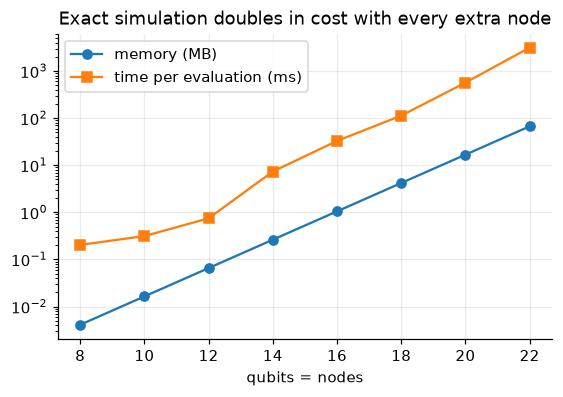

Each +1 node doubles memory and time. 50 nodes -> petabytes; this is why a hybrid decomposition is needed.


In [14]:
rows = []
for nn in range(8, 23, 2):
    Gs = make_social_graph(nn, m=2, seed=nn); dd = cut_diagonal(Gs)
    t0 = time.time(); _ = qaoa_probs(dd, nn, [0.5, 0.4], [0.3, 0.2]); dt = time.time() - t0
    rows.append(dict(qubits=nn, state_MB=16 * 2**nn / 1e6, seconds_per_evaluation=dt))
df_sv = pd.DataFrame(rows); display(df_sv.round(4)); R["statevector_scaling"] = df_sv.round(5).to_dict("records")
fig, ax = plt.subplots(figsize=(5.8, 3.6)); ax.semilogy(df_sv.qubits, df_sv.state_MB, "o-", label="memory (MB)"); ax.semilogy(df_sv.qubits, df_sv.seconds_per_evaluation*1000, "s-", label="time per evaluation (ms)")
ax.set(xlabel="qubits = nodes", title="Exact simulation doubles in cost with every extra node"); ax.legend(); fig.savefig(FIGS / "statevector_scaling.png", bbox_inches="tight"); plt.show()
print("Each +1 node doubles memory and time. 50 nodes -> petabytes; this is why a hybrid decomposition is needed.")

### 12b. Block-QAOA hybrid vs classical heuristics on growing scale-free social graphs
Barabási–Albert graphs (hub-heavy like real social networks), integer weights 1–3. Blocks of 12 qubits, depth p = 2, 3 sweeps. A block update is only accepted if it does not lower the cut.

In [15]:
SCALE = []; SIZES = [100, 300, 1000, 3000]
for N in SIZES:
    H = make_social_graph(N, m=3, seed=N); Wt = sum(d["weight"] for *_, d in H.edges(data=True))
    t0 = time.time(); bq = block_qaoa(H, block_size=12, p=2, sweeps=3, shots=1024, max_iter=60, seed=1); t_bq = time.time() - t0
    t0 = time.time(); g_ = greedy_flip(H, restarts=3, seed=1); t_g = time.time() - t0
    t0 = time.time(); s_ = spectral_bisection(H); t_s = time.time() - t0
    row = dict(nodes=N, edges=H.number_of_edges(), total_weight=Wt, random=float(Wt / 2), block_qaoa=bq["cut"], greedy=g_[0], spectral=s_[0],
               qaoa_sec=t_bq, greedy_sec=t_g, spectral_sec=t_s, blocks_solved=bq["blocks_solved"], sec_per_block=bq["seconds"] / bq["blocks_solved"], trace=bq["trace"])
    if N <= 100:
        gwa, gwb, ub, _ = goemans_williamson(H, trials=20); row.update(gw_best=gwb, sdp_upper_bound=ub)
    SCALE.append(row); print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in row.items() if k != "trace"}, flush=True)
df_scale = pd.DataFrame(SCALE); R["block_qaoa_scaling"] = df_scale.to_dict("records")
display(df_scale.drop(columns=["trace"]).round(2))

{'nodes': 100, 'edges': 291, 'total_weight': 606.0, 'random': 303.0, 'block_qaoa': 464.0, 'greedy': 457.0, 'spectral': 394.0, 'qaoa_sec': 1.88, 'greedy_sec': 0.0, 'spectral_sec': 0.02, 'blocks_solved': 32, 'sec_per_block': 0.06, 'gw_best': 468.0, 'sdp_upper_bound': 500.12}


{'nodes': 300, 'edges': 891, 'total_weight': 1776.0, 'random': 888.0, 'block_qaoa': 1365.0, 'greedy': 1329.0, 'spectral': 1153.0, 'qaoa_sec': 5.25, 'greedy_sec': 0.01, 'spectral_sec': 0.01, 'blocks_solved': 98, 'sec_per_block': 0.05}


{'nodes': 1000, 'edges': 2991, 'total_weight': 5930.0, 'random': 2965.0, 'block_qaoa': 4488.0, 'greedy': 4462.0, 'spectral': 3855.0, 'qaoa_sec': 15.45, 'greedy_sec': 0.03, 'spectral_sec': 0.01, 'blocks_solved': 327, 'sec_per_block': 0.05}


{'nodes': 3000, 'edges': 8991, 'total_weight': 18141.0, 'random': 9070.5, 'block_qaoa': 13811.0, 'greedy': 13562.0, 'spectral': 12235.0, 'qaoa_sec': 48.25, 'greedy_sec': 0.4, 'spectral_sec': 0.02, 'blocks_solved': 967, 'sec_per_block': 0.05}


,nodes,edges,total_weight,random,block_qaoa,greedy,spectral,qaoa_sec,greedy_sec,spectral_sec,blocks_solved,sec_per_block,gw_best,sdp_upper_bound
0,100,291,606.0,303.0,464.0,457.0,394.0,1.88,0.00,0.02,32,0.06,468.0,500.12
1,300,891,1776.0,888.0,1365.0,1329.0,1153.0,5.25,0.01,0.01,98,0.05,NaN,NaN
2,1000,2991,5930.0,2965.0,4488.0,4462.0,3855.0,15.45,0.03,0.01,327,0.05,NaN,NaN
3,3000,8991,18141.0,9070.5,13811.0,13562.0,12235.0,48.25,0.40,0.02,967,0.05,NaN,NaN


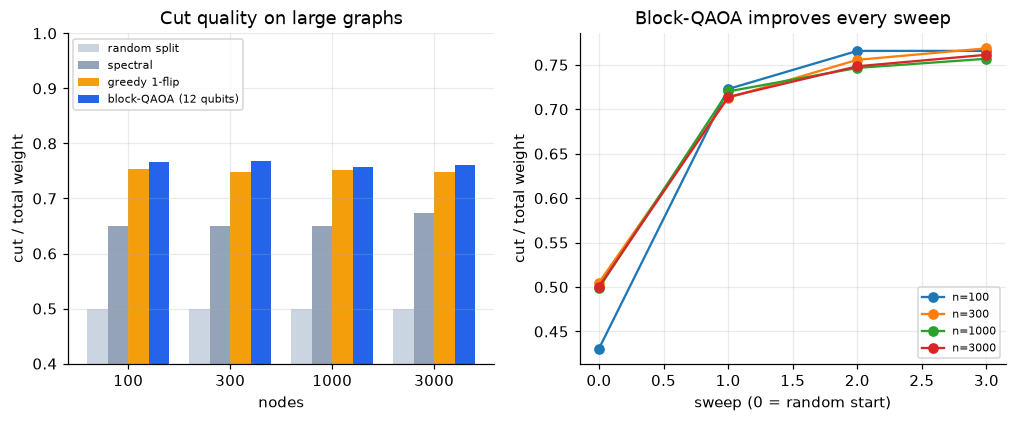

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
x = np.arange(len(SIZES)); wd = .2
for i, (col, lab, c) in enumerate([("random", "random split", "#cbd5e1"), ("spectral", "spectral", "#94a3b8"), ("greedy", "greedy 1-flip", C_CUT), ("block_qaoa", "block-QAOA (12 qubits)", C_A)]):
    axs[0].bar(x + (i - 1.5) * wd, df_scale[col] / df_scale.total_weight, wd, label=lab, color=c)
axs[0].set_xticks(x); axs[0].set_xticklabels(SIZES); axs[0].set(xlabel="nodes", ylabel="cut / total weight", title="Cut quality on large graphs"); axs[0].legend(fontsize=7, loc="upper left"); axs[0].set_ylim(.4, 1)
for r_ in SCALE: axs[1].plot(range(len(r_["trace"])), np.array(r_["trace"]) / r_["total_weight"], "o-", label=f"n={r_['nodes']}")
axs[1].set(xlabel="sweep (0 = random start)", ylabel="cut / total weight", title="Block-QAOA improves every sweep"); axs[1].legend(fontsize=7, loc="lower right")
fig.savefig(FIGS / "block_qaoa_scaling.png", bbox_inches="tight"); plt.show()

### 12c. A 20,000-node run, and what 1 million / 5 million nodes would require
We time one sweep on 20,000 nodes, then extrapolate using the *measured* time per 12-qubit block. Qubit count stays at 12 per block; only the number of blocks grows (and blocks of different regions can run on different devices in parallel).

In [17]:
N_BIG = 20000
Hb = make_social_graph(N_BIG, m=3, seed=5); Wb = sum(d["weight"] for *_, d in Hb.edges(data=True))
bq_big = block_qaoa(Hb, block_size=12, p=2, sweeps=1, shots=1024, max_iter=40, seed=2)
gr_big = greedy_flip(Hb, restarts=1, seed=2)
print(f"{N_BIG} nodes / {Hb.number_of_edges()} edges: block-QAOA 1 sweep cut ratio {bq_big['cut']/Wb:.3f} ({bq_big['seconds']:.0f}s, {bq_big['blocks_solved']} blocks of 12 qubits); greedy {gr_big[0]/Wb:.3f}; random 0.500")
t_block = bq_big["seconds"] / bq_big["blocks_solved"]
rows = []
def _hms(sec):
    if sec < 1:
        return "<1 s"
    if sec < 120:
        return f"{sec:.0f} s"
    if sec < 7200:
        return f"{sec/60:.1f} min"
    return f"{sec/3600:.1f} h"
for N in (1e4, 1e5, 1e6, 5e6, 5e8):
    mm = 3 * N; blocks = int(np.ceil(N * bq_big['blocks_solved'] / N_BIG))  # measured blocks per node (BFS blocks average < k nodes)
    rows.append(dict(nodes=f"{N:,.0f}", monolithic_qubits=f"{N:,.0f}", monolithic_rzz_gates_p2=f"{2*mm:,.0f}", block_qubits=12, blocks_per_sweep=f"{blocks:,}",
                     one_sweep_1_core=_hms(blocks * t_block), one_sweep_1000_workers=_hms(blocks * t_block / 1000)))
df_ext = pd.DataFrame(rows); display(df_ext)
R["large_run"] = dict(nodes=N_BIG, edges=Hb.number_of_edges(), block_qaoa_ratio=bq_big["cut"] / Wb, greedy_ratio=gr_big[0] / Wb, seconds=bq_big["seconds"], blocks=bq_big["blocks_solved"], sec_per_block=t_block)
R["extrapolation"] = rows

20000 nodes / 59991 edges: block-QAOA 1 sweep cut ratio 0.714 (69s, 2187 blocks of 12 qubits); greedy 0.746; random 0.500


,nodes,monolithic_qubits,monolithic_rzz_gates_p2,block_qubits,blocks_per_sweep,one_sweep_1_core,one_sweep_1000_workers
0,"10,000","10,000","60,000",12,"1,094",35 s,<1 s
1,"100,000","100,000","600,000",12,"10,935",5.8 min,<1 s
2,"1,000,000","1,000,000","6,000,000",12,"109,350",57.6 min,3 s
3,"5,000,000","5,000,000","30,000,000",12,"546,750",4.8 h,17 s
4,"500,000,000","500,000,000","3,000,000,000",12,"54,675,000",480.3 h,28.8 min


### Plain-language answer for the guide's question
> *"What will you do with 15–16 nodes for Instagram-scale analysis?"*

1. **16 nodes is the validation size, not the target.** It is the largest size where we can check QAOA against the exact brute-force answer, so it proves the quantum routine is correct.
2. **We never need one 5-million-qubit circuit.** The framework splits the network into small blocks, solves each block (12 qubits here, 50–100 on today's hardware) with QAOA, holds the rest fixed, and sweeps. Section 12b/12c runs this on up to **20,000 users**.
3. **Cost grows linearly with users, not exponentially**: the number of blocks is proportional to $N$ (about $N/9$ measured for $k=12$ because BFS blocks are often smaller than $k$); every block has the same cost and blocks can run in parallel (12c table).
4. **What we do not claim:** a quantum speed-up over classical heuristics on these sizes. On small blocks classical heuristics are as good; the contribution is a working hybrid architecture, honest benchmarks, and a path to hardware as qubit counts and fidelities grow.

## Findings (read before quoting any number)
* **Correct and verified:** our simulator matches Qiskit to $10^{-17}$; brute force confirms the optimum (44) and takes milliseconds.
* **QAOA concentrates probability on good cuts:** the chance that one measurement is an optimal cut is roughly 100x the chance of hitting it by uniform guessing ($6/2^{16}$), and the
  expected cut ratio is about 0.8 at p = 1–3 (random split: 0.59).
* **On 16 nodes classical methods are as good or better** (greedy 1-flip reaches 44 instantly; Goemans–Williamson best-of-20 reaches 44). Pure random sampling of 2048 strings also finds 42–44. We therefore do **not** claim a quantum advantage.
* **Louvain** maximises modularity, which *minimises* cut edges between communities; as a Max-Cut solver it is not meaningful (its 2-way merge scores far below the others).
* **Noise matters:** on a simulated 127-qubit IBM Eagle, expected cut drops as the circuit deepens (p = 2 is worse than p = 1).
* **Scaling:** the block-QAOA architecture runs on 100–20,000 nodes with 12-qubit blocks, tracking or beating one-sweep classical heuristics at moderate size; time per block is constant, so cost grows linearly with graph size.
  The 1M / 5M-node rows are *extrapolations of simulated block time*, not measurements, and real hardware adds queueing and shot latency.

## 13. Save results
Everything above is written to `results/results.json` (used for the paper and the web demo).

In [18]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)):
        value = float(o)
        return value if np.isfinite(value) else None
    if isinstance(o, np.ndarray): return o.tolist()
    return o
out = ROOT / "results" / "results.json"; out.write_text(json.dumps(_clean(R), indent=2)); print("saved", out)

saved /home/viraj/Documents/QAOA-QC/results/results.json
